Train samples: (50000, 32, 32, 3) (50000, 1)
Test samples: (10000, 32, 32, 3) (10000, 1)
Epoch 1/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 20s 13ms/step - accuracy: 0.3295 - loss: 1.8818 - val_accuracy: 0.4318 - val_loss: 1.6333
Epoch 2/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 17s 12ms/step - accuracy: 0.4502 - loss: 1.5519 - val_accuracy: 0.4714 - val_loss: 1.4993
Epoch 3/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 19s 13ms/step - accuracy: 0.4890 - loss: 1.4337 - val_accuracy: 0.4832 - val_loss: 1.4670
Epoch 4/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 19s 14ms/step - accuracy: 0.5230 - loss: 1.3484 - val_accuracy: 0.4842 - val_loss: 1.4643
Epoch 5/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 18s 13ms/step - accuracy: 0.5459 - loss: 1.2772 - val_accuracy: 0.5066 - val_loss: 1.4191
Epoch 6/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 19s 12ms/step - accuracy: 0.5731 - loss: 1.2089 - val_accuracy: 0.5098 - val_loss: 1.3987
Epoch 7/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 18s 13ms/step - accuracy: 0.5946 - loss: 1.1353 - val_accuracy: 0.5252 - val_

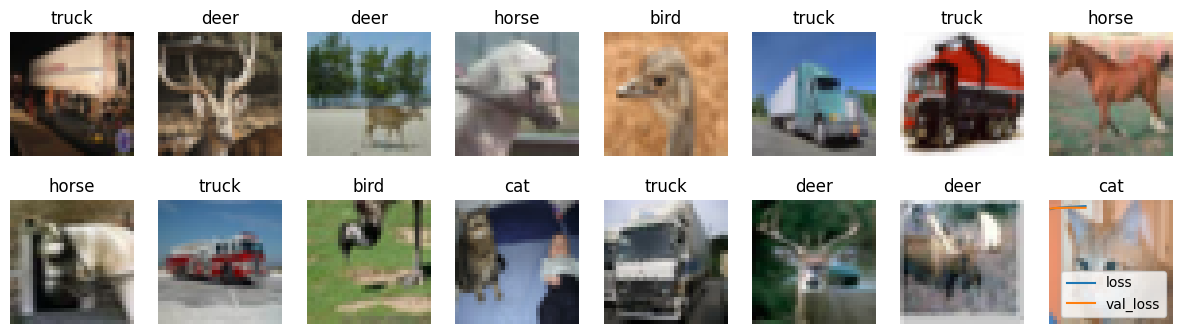

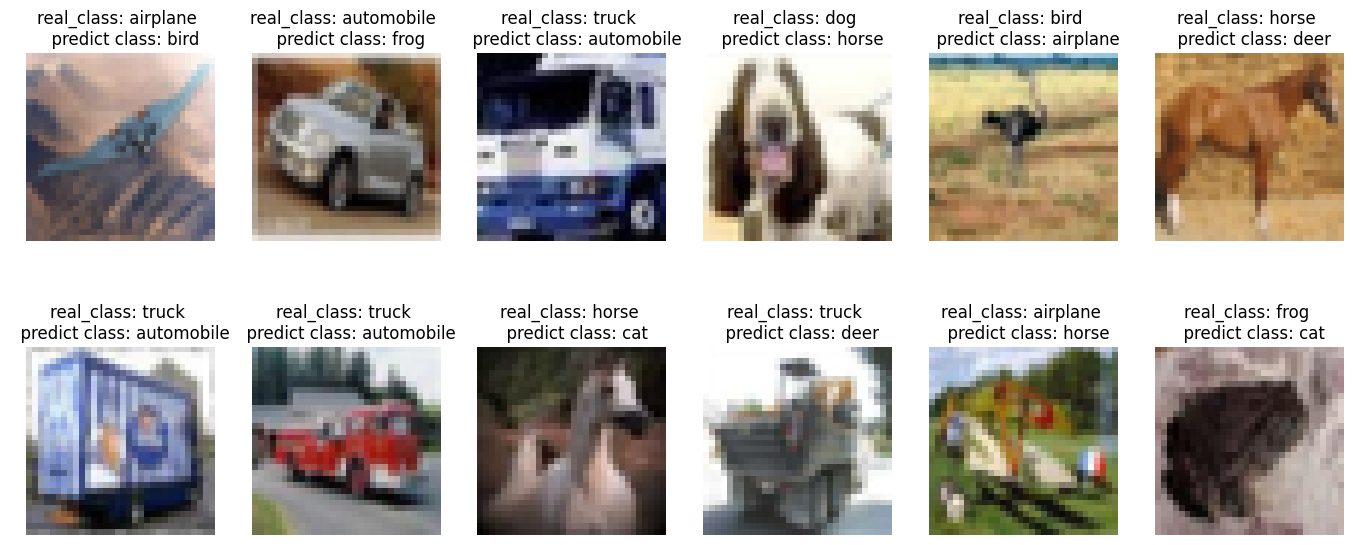

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step


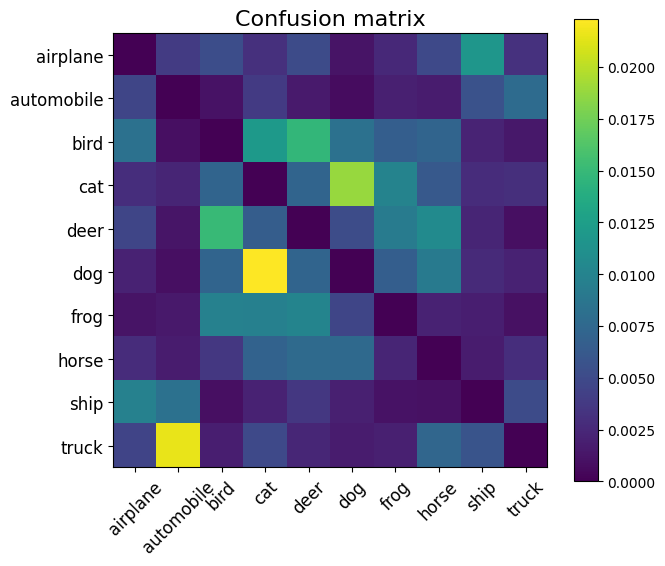

In [ ]:
import numpy as np
import random
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras import layers, models, Model, Sequential
from sklearn.metrics import confusion_matrix, accuracy_score

(X_train, y_train), (X_test, y_test) = tf.keras.datasets.cifar10.load_data()

NUM_CLASSES = 10
cifar10_classes = ["airplane", "automobile", "bird", "cat", "deer",
                   "dog", "frog", "horse", "ship", "truck"]

print("Train samples:", X_train.shape, y_train.shape)
print("Test samples:", X_test.shape, y_test.shape)

cols = 8
rows = 2
fig = plt.figure(figsize=(2 * cols - 1, 2.5 * rows - 1))
for i in range(cols):
    for j in range(rows):
        random_index = np.random.randint(0, len(y_train))
        ax = fig.add_subplot(rows, cols, i * rows + j + 1)
        ax.grid('off')
        ax.axis('off')
        ax.imshow(X_train[random_index, :])
        ax.set_title(cifar10_classes[y_train[random_index, 0]])
X_train_n, X_test_n = X_train / 127.5 - 1, X_test / 127.5 - 1
X_train_n.max(), X_train_n.min()

model_fc = Sequential()
model_fc.add(layers.Flatten(input_shape=(32, 32, 3)))

for unit in [256, 128, 64, 32]:
    model_fc.add(layers.Dense(unit, activation='relu'))

model_fc.add(layers.Dense(10, activation='softmax'))
model_fc(X_train[:2])

model_fc.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(),
              metrics=['accuracy'])

history_fc = model_fc.fit(
    X_train_n, y_train,
    batch_size = 32,
    epochs = 10,
    validation_split=0.1,
    verbose=1
)
model_fc.evaluate(X_test_n,  y_test, verbose=2)

plt.plot(history_fc.history['loss'], label='loss')
plt.plot(history_fc.history['val_loss'], label = 'val_loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(loc='lower right');

y_pred = np.argmax(model_fc.predict(X_test_n), axis=1)
errors =  y_pred != y_test.T[0]
errors[:5]
X_err = X_test[errors]
y_err = y_test[errors].T[0]
y_pred = y_pred[errors]
cols = 6
rows = 2
fig = plt.figure(figsize=(3 * cols - 1, 4 * rows - 1))
for i in range(cols):
    for j in range(rows):
        random_index = np.random.randint(0, len(y_err))
        ax = fig.add_subplot(rows, cols, i * rows + j + 1)
        ax.grid('off')
        ax.axis('off')
        ax.imshow(X_err[random_index, : ], cmap='gray')
        ax.set_title('real_class: {} \n  predict class: {}'.format(cifar10_classes[y_err[random_index]],
                                                                   cifar10_classes[y_pred[random_index]]))
plt.show()

p_pred = model_fc.predict(X_test_n)
y_pred = np.argmax(p_pred, axis=1)

cm = confusion_matrix(y_test.T[0], y_pred, normalize='all')
cm = cm - np.eye(NUM_CLASSES)*cm.diagonal()

plt.figure(figsize=(7, 6))
plt.title('Confusion matrix', fontsize=16)
plt.imshow(cm)
plt.xticks(np.arange(10), cifar10_classes, rotation=45, fontsize=12)
plt.yticks(np.arange(10), cifar10_classes, fontsize=12)
plt.colorbar();

Epoch 1/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 47s 31ms/step - accuracy: 0.4449 - loss: 1.5565 - val_accuracy: 0.5954 - val_loss: 1.1182
Epoch 2/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 82s 31ms/step - accuracy: 0.6308 - loss: 1.0478 - val_accuracy: 0.6552 - val_loss: 0.9855
Epoch 3/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 41s 29ms/step - accuracy: 0.6883 - loss: 0.8901 - val_accuracy: 0.6560 - val_loss: 1.0076
Epoch 4/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 40s 28ms/step - accuracy: 0.7262 - loss: 0.7757 - val_accuracy: 0.6712 - val_loss: 0.9763
Epoch 5/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 40s 29ms/step - accuracy: 0.7670 - loss: 0.6708 - val_accuracy: 0.6780 - val_loss: 0.9644
Epoch 6/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 40s 29ms/step - accuracy: 0.7934 - loss: 0.5850 - val_accuracy: 0.6698 - val_loss: 1.0229
Epoch 7/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 41s 29ms/step - accuracy: 0.8216 - loss: 0.5108 - val_accuracy: 0.6762 - val_loss: 1.0843
Epoch 8/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 41s 29ms/step - accuracy: 0.8436 -

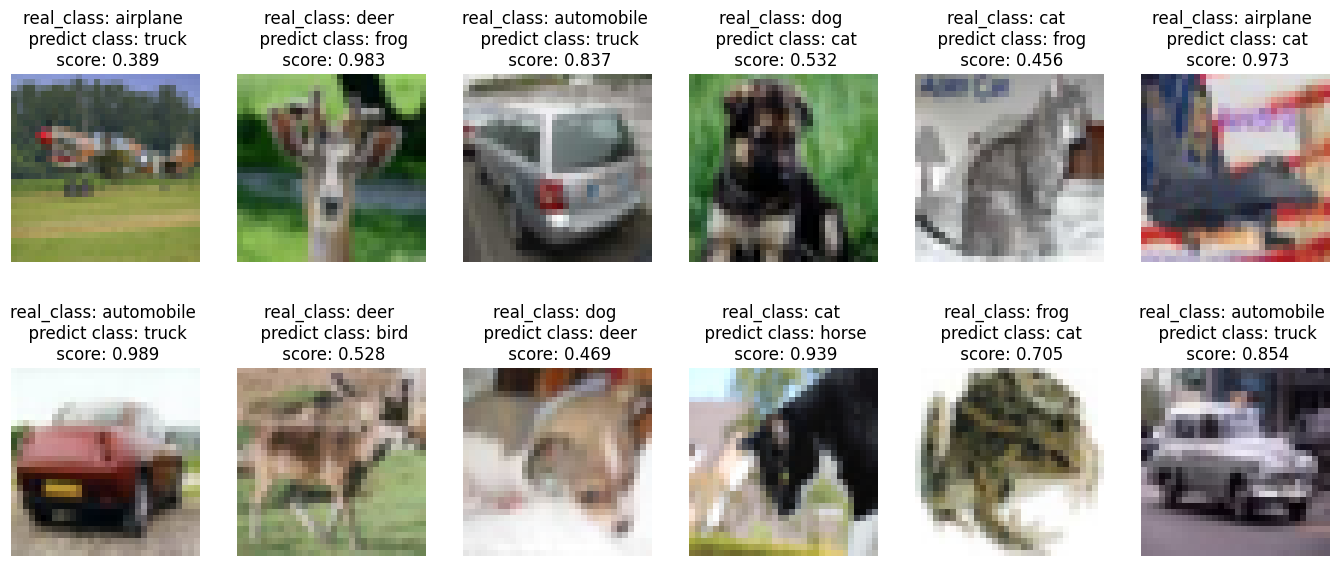

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step


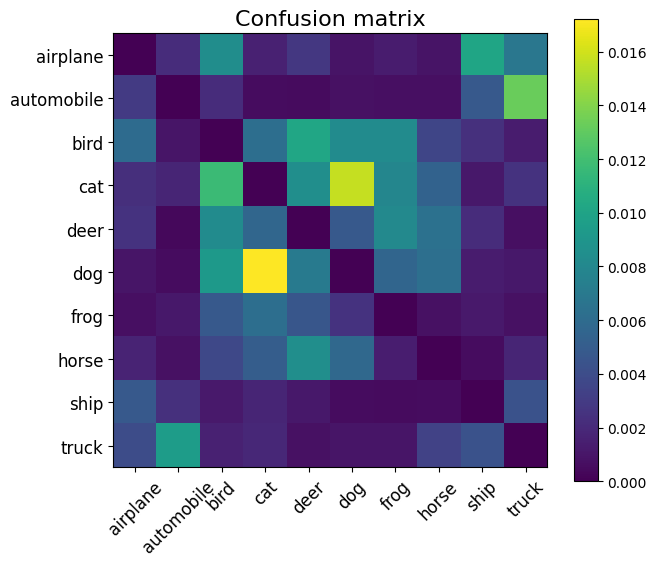

In [ ]:
from sklearn.metrics import confusion_matrix, accuracy_score
model_cnn = Sequential([

    layers.Conv2D(16, kernel_size=(3,3),
                padding='same', activation='elu'),
    layers.AvgPool2D(pool_size=(2, 2)),

    layers.Conv2D(32, kernel_size=(3,3),
                padding='same', activation='elu'),
    layers.MaxPool2D(pool_size=(2, 2)),

    layers.Flatten(),
    layers.Dense(64, activation='elu', name='fc_embedding_128'),
    layers.Dense(32, activation='elu', name='fc_embedding_64'),
    layers.Dense(10, activation='softmax')
])
# параметры изменены глубины, количества нейронов и функций активаций
model_cnn.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(),
              metrics=['accuracy'])

history_cnn = model_cnn.fit(
    X_train_n, y_train,
    batch_size = 32,
    epochs = 10,
    validation_split=0.1,
    verbose=1
)
model_cnn.evaluate(X_test_n,  y_test, verbose=2)

p_pred = model_cnn.predict(X_test_n)
y_pred = np.argmax(p_pred, axis=1)
errors =  y_pred != y_test.T[0]

X_err = X_test[errors]
y_err = y_test[errors].T[0]
y_pred = y_pred[errors]
p_pred = p_pred[errors]

cols = 6
rows = 2
fig = plt.figure(figsize=(3 * cols - 1, 4 * rows - 1))
for i in range(cols):
    for j in range(rows):
        random_index = np.random.randint(0, len(y_err))
        ax = fig.add_subplot(rows, cols, i * rows + j + 1)
        ax.grid('off')
        ax.axis('off')
        ax.imshow(X_err[random_index, : ], cmap='gray')
        ax.set_title('real_class: {} \n  predict class: {} \n score: {:.3}'.format(cifar10_classes[y_err[random_index]],
                                                                   cifar10_classes[y_pred[random_index]], np.max(p_pred[random_index])))
plt.show()

p_pred = model_cnn.predict(X_test_n)
y_pred = np.argmax(p_pred, axis=1)

cm = confusion_matrix(y_test.T[0], y_pred, normalize='all')
cm = cm - np.eye(NUM_CLASSES)*cm.diagonal()

plt.figure(figsize=(7, 6))
plt.title('Confusion matrix', fontsize=16)
plt.imshow(cm)
plt.xticks(np.arange(10), cifar10_classes, rotation=45, fontsize=12)
plt.yticks(np.arange(10), cifar10_classes, fontsize=12)
plt.colorbar();

Модель практически не изменилась, стало чуть-чуть лучше, но все равно плохая